# 02 · Data quality assessment
Profiling the **raw staging layer** before deciding any cleaning rule. Each issue is quantified, its business impact is stated,
and a rule is proposed. The rules are implemented in `src/data_cleaning.py` and applied in notebook 03.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # project root, so `src` is importable
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
engine = get_engine()

## 1. Duplicates
Distinct keys versus raw rows. Duplicate keys whose content is identical are safe to drop; keys with *different* content would need a business decision.

In [2]:
an.sql_output('dq_a01_row_counts').assign(extra_rows=lambda d: d.raw_rows - d.distinct_keys)

,table_name,raw_rows,distinct_keys,extra_rows
0,customers,9090,9000,90
1,inventory,249985,249487,498
2,products,203,203,0
3,promotions,110,110,0
4,transaction_items,1205079,1201475,3604
5,transactions,291157,289998,1159


In [3]:
an.sql_output('dq_a02_exact_duplicate_items')

,duplicated_keys,extra_rows,conflicting_keys
0,3604,"3,604.00",0


All duplicated item keys are exact copies (`conflicting_keys = 0`). Left in, they would overstate revenue by roughly the duplicate share, so the rule is **drop exact copies and fail loudly on conflicts**.

## 2. Missing values

In [4]:
an.sql_output('dq_a03_missing_values').assign(pct=lambda d: 100*d.missing/d.total)

,field,missing,total,pct
0,products.brand,6,203,2.96
1,products.unit_cost,3,203,1.48
2,customers.county,362,9090,3.98
3,transactions.payment_method,5823,291157,2.00
4,transactions.customer_id (anonymous),111073,291157,38.15


- **Anonymous baskets** (`customer_id` NULL) are *not* an error. They are cash or card customers without a loyalty card, so they are kept.
- **Missing payment method** (about 2%): kept as `Unknown`. It does not affect revenue.
- **Missing unit_cost** (3 SKUs): gross profit cannot be computed for these, so cost is imputed from the category's median cost-to-price ratio and **flagged** (`unit_cost_imputed`).
- **Missing customer county** (4%): left NULL and reported as Unknown. Imputing it from the home branch would be a guess.

## 3. Inconsistent labels

In [5]:
an.sql_output('dq_a04_category_labels')

,category,products
0,Baby Care,11
1,baby care,1
2,Bakery,15
3,BEVERAGES,2
4,Beverages,22
5,Dairy,16
6,dairy,2
7,Fresh Produce,23
8,Fresh produce,1
9,Household & Cleaning,20


In [6]:
an.sql_output('dq_a05_payment_labels')

,payment_method,transactions
0,Mobile Money,156937
1,Cash,59754
2,Card,46318
3,Voucher,8452
4,<NULL>,5823
5,M-Money,2828
6,MOBILE MONEY,2755
7,mobile money,2700
8,CASH,1608
9,cash,1567


Ten real categories appear under 19 spellings. Without standardisation a category chart would split Dairy across three bars. Rule: map to the canonical list by case-, whitespace- and '&'/'and'-insensitive matching, and **stop if any label cannot be mapped**.

## 4. Invalid dates and orphan keys

In [7]:
an.sql_output('dq_a06_invalid_dates')

,year_text,transactions
0,2024,25614
1,2025,141019
2,2026,124503
3,2052,14
4,2062,7


In [8]:
an.sql_output('dq_a07_orphan_keys')

,relationship,orphan_rows
0,transactions -> branches,40
1,transactions -> customers,0
2,items -> products,0


Years such as 2052 and 2062 are clearly keying errors (digits transposed). They *could* be corrected, but which digit is wrong is a guess, so they are **quarantined**. The 40 receipts pointing to branch `BR99` cannot be attributed to a store and are also quarantined, together with their lines.

## 5. Quantity outliers: investigate, don't delete
The key question: which large quantities are real bulk purchases, and which are errors?

In [9]:
an.sql_output('dq_a08_quantity_profile')

,quantity_band,lines,min_q,max_q
0,a) negative (return),3006,-3,-1
1,b) 1-10,1186774,1,10
2,c) 11-60,15239,11,52
3,e) 100+,60,100,400


In [10]:
q = query(engine, """SELECT i.quantity::int AS quantity, COALESCE(c.customer_segment, 'Anonymous') AS segment
FROM staging.transaction_items i
JOIN (SELECT DISTINCT ON (transaction_id) transaction_id, customer_id FROM staging.transactions) t USING (transaction_id)
LEFT JOIN (SELECT DISTINCT ON (customer_id) customer_id, initcap(customer_segment) AS customer_segment FROM staging.customers) c USING (customer_id)
WHERE i.quantity::int > 10""")
q["segment"] = q["segment"].str.title()
summary = q.groupby("segment").quantity.describe(percentiles=[.5, .99])
summary

,count,mean,std,min,50%,99%,max
segment,,,,,,,
Anonymous,22.00,122.73,68.53,100.00,100.00,358.00,400.00
Household,28.00,146.43,63.72,100.00,100.00,300.00,300.00
Senior,2.00,100.00,0.00,100.00,100.00,100.00,100.00
Small Business,"15,239.00",15.39,3.96,11.00,14.00,30.00,52.00
Young Professional,8.00,112.50,35.36,100.00,100.00,193.00,200.00


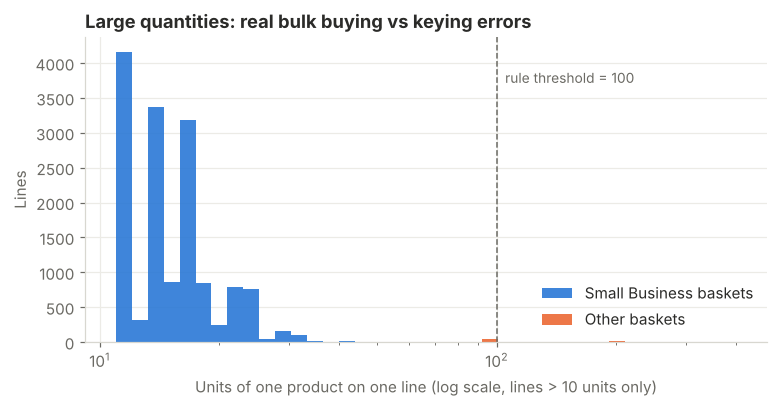

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sb = q[q.segment == "Small Business"].quantity
other = q[q.segment != "Small Business"].quantity
bins = np.logspace(np.log10(11), np.log10(q.quantity.max() + 1), 40)
ax.hist(sb, bins=bins, color=an.PRIMARY, label="Small Business baskets", alpha=.9)
ax.hist(other, bins=bins, color=an.HIGHLIGHT, label="Other baskets", alpha=.9)
ax.set_xscale("log"); ax.axvline(100, color=an.INK_MUTED, ls="--", lw=1)
ax.text(105, ax.get_ylim()[1]*.85, "rule threshold = 100", color=an.INK_MUTED, fontsize=9)
ax.set_xlabel("Units of one product on one line (log scale, lines > 10 units only)"); ax.set_ylabel("Lines")
ax.set_title("Large quantities: real bulk buying vs keying errors"); ax.legend()
an.save(fig, "dq_quantity_outliers");

**Finding.** Small Business customers legitimately buy up to about 50 units of a staple. Every line from a *non-business* basket with more than 10 units sits at 100 or above, a clean ×100 pattern (2 typed as 200). Rule: quarantine lines with quantity ≥ 100 **unless** the basket belongs to a Small Business customer. Bulk lines are kept, because deleting them would understate Staples sales to the trade segment.

Negative quantities (-1 to -3) are **returns**. They move to `retail.returns`, so they neither inflate nor offset sales revenue.

## 6. Prices, inventory and promotions

In [12]:
pd.concat([an.sql_output('dq_a09_zero_or_negative_prices'), an.sql_output('dq_a10_inventory_anomalies')], axis=1)

,zero_price_lines,negative_price_lines,negative_stock_rows,duplicate_snapshot_rows
0,35,0,50,498


In [13]:
an.sql_output('dq_a11_promotion_date_logic')

,promotion_id,start_date,end_date
0,PR035,2026-01-29,2026-01-16
1,PR100,2026-03-02,2026-02-17


| Issue | Rule | Why |
|---|---|---|
| Zero unit price (35 lines) | impute the product's modal shelf price, flag `price_imputed` | shelf prices are stable per SKU; zero would understate revenue and make margin −100% |
| Negative closing stock (50 rows) | set to 0 and log it | stock cannot physically be negative; it happens when sales post before goods are receipted |
| Promotion end date before start date (2) | swap the dates | the duration and product are valid, only the order is wrong |

## 7. Cross-check against the generator's injection manifest
Because the data is synthetic, the generator recorded what it injected. Detection should match it.

In [14]:
manifest = json.loads((PROJECT_ROOT / "data/synthetic/raw/injection_manifest.json").read_text())
log = an.sql_output("dq_b03_exception_log")
pairs = [("items_exact_duplicates", "transaction_items", "exact duplicate row"),
         ("items_return_lines", "transaction_items", "negative quantity"),
         ("items_quantity_typo_x100", "transaction_items", "quantity >= 100 on non-business basket"),
         ("items_zero_price", "transaction_items", "zero unit_price"),
         ("transactions_exact_duplicates", "transactions", "exact duplicate row"),
         ("transactions_orphan_branch", "transactions", "branch_id not in branch master"),
         ("transactions_invalid_future_year", "transactions", "timestamp outside data period (likely year typo)"),
         ("inventory_negative_stock", "inventory", "negative stock count (sold before receipt posted)"),
         ("customers_exact_duplicates", "customers", "exact duplicate row"),
         ("products_missing_unit_cost", "products", "missing unit_cost")]
rows = []
for key, tbl, issue in pairs:
    found = log[(log.source_table == tbl) & (log.issue == issue)].records.sum()
    rows.append({"injected_issue": key, "injected": manifest[key], "detected_and_handled": found})
pd.DataFrame(rows).assign(match=lambda d: d.injected == d.detected_and_handled)

,injected_issue,injected,detected_and_handled,match
0,items_exact_duplicates,3604,3604,True
1,items_return_lines,2996,2996,True
2,items_quantity_typo_x100,60,60,True
3,items_zero_price,35,35,True
4,transactions_exact_duplicates,1159,1159,True
5,transactions_orphan_branch,40,40,True
6,transactions_invalid_future_year,21,21,True
7,inventory_negative_stock,50,50,True
8,customers_exact_duplicates,90,90,True
9,products_missing_unit_cost,3,3,True


Every injected problem is detected and handled, and the counts match. The quantity rule caught exactly the injected keying errors and none of the genuine bulk lines. This check is possible only because the data is synthetic; with real data, the equivalent is a sample audit with the business.